# TECH 405 RNN Hackathon: SMS Spam Classification with an LSTM

**Dataset:** SMS Spam Collection (5,572 text messages labelled `ham` or `spam`).
**Task:** binary classification. **Baseline (majority class):** 86.6%. **Target:** 96%.
**Model:** `nn.Embedding` then `nn.LSTM` then `nn.Linear` (PyTorch, trained from scratch, no pretrained models).

**Why this is a sequence problem:** a text message is an ordered list of words, and the meaning depends on the order and context of the words (for example "free entry" or "call now to claim"). An LSTM reads the words one by one and keeps a memory of what it has seen, so the final hidden state summarises the whole message.

## 1. Imports and settings

In [1]:
import os, random, re, time
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch, torch.nn as nn
from torch.nn.utils.rnn import pack_padded_sequence
from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report

torch.set_num_threads(4)
os.makedirs("figures", exist_ok=True)

def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s)

SEED = 42
set_seed(SEED)

MAXLEN, EMB, HID, BATCH, LR, EPOCHS = 60, 64, 64, 64, 2e-3, 15
print("torch", torch.__version__)

torch 2.14.1+cu130


## 2. Load the data (snapshot 1: data and shapes)

In [2]:
url = "https://raw.githubusercontent.com/mohitgupta-omg/Kaggle-SMS-Spam-Collection-Dataset-/master/spam.csv"
path = "data/spam.csv"
df = pd.read_csv(path if os.path.exists(path) else url, encoding="latin-1")[["v1", "v2"]]
df.columns = ["label", "text"]
df["y"] = (df["label"] == "spam").astype(int)

print("Dataset shape:", df.shape)
print(df["label"].value_counts().to_string())
print("Median words per message:", int(df["text"].str.split().str.len().median()),
      "| longest:", df["text"].str.split().str.len().max())
display(df.head(3))

Dataset shape: (5572, 3)
label
ham     4825
spam     747
Median words per message: 12 | longest: 171


,label,text,y
0,ham,"Go until jurong point, crazy.. Available only ...",0
1,ham,Ok lar... Joking wif u oni...,0
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,1


## 3. Tokenise, build the vocabulary, and make the fixed 80/20 split
The vocabulary is built from the **training** messages only. The test set is never used for any choice. A further 10% of the training data is held out as a validation set for choosing the best epoch.

In [3]:
def tokenize(t):
    return re.findall(r"[a-z0-9']+|[^\sa-z0-9]", t.lower())

# fixed 80/20 split (stratified so both parts keep the same spam ratio)
train_df, test_df = train_test_split(df, test_size=0.20, random_state=42, stratify=df["y"])
train_df, val_df = train_test_split(train_df, test_size=0.10, random_state=42, stratify=train_df["y"])

counts = Counter(tok for t in train_df["text"] for tok in tokenize(t))
itos = ["<pad>", "<unk>"] + [w for w, c in counts.items() if c >= 2]
stoi = {w: i for i, w in enumerate(itos)}
VOCAB = len(itos)

def encode(t):
    ids = [stoi.get(tok, 1) for tok in tokenize(t)][:MAXLEN]
    return ids, max(len(ids), 1)

class SMS(Dataset):
    def __init__(self, d):
        enc = [encode(t) for t in d["text"]]
        self.x = torch.zeros(len(enc), MAXLEN, dtype=torch.long)
        for i, (ids, _) in enumerate(enc):
            self.x[i, :len(ids)] = torch.tensor(ids)
        self.len = torch.tensor([l for _, l in enc])
        self.y = torch.tensor(d["y"].values)
    def __len__(self): return len(self.y)
    def __getitem__(self, i): return self.x[i], self.len[i], self.y[i]

train_ds, val_ds, test_ds = SMS(train_df), SMS(val_df), SMS(test_df)
BASELINE = 1 - test_df["y"].mean()      # always guess "ham"

print("Train / val / test sizes:", len(train_ds), len(val_ds), len(test_ds))
print("Vocabulary size:", VOCAB)
print("One batch of X:", train_ds.x[:BATCH].shape, "(batch, MAXLEN)   y:", train_ds.y[:BATCH].shape)
print(f"Majority-class baseline on the test set: {BASELINE*100:.1f}%")

Train / val / test sizes: 4011 446 1115
Vocabulary size: 3581
One batch of X: torch.Size([64, 60]) (batch, MAXLEN)   y: torch.Size([64])
Majority-class baseline on the test set: 86.6%


## 4. Model definition (snapshot 2)
`nn.Embedding` turns each word id into a vector, `nn.LSTM` reads the sequence, and `nn.Linear` maps the last hidden state to the 2 classes. The same class can use `nn.RNN` instead, which is used later for a comparison.

In [4]:
class Classifier(nn.Module):
    def __init__(self, cell="LSTM", vocab=VOCAB, emb=EMB, hid=HID, classes=2):
        super().__init__()
        self.cell = cell
        self.embed = nn.Embedding(vocab, emb, padding_idx=0)
        rnn = {"LSTM": nn.LSTM, "RNN": nn.RNN}[cell]
        self.rnn = rnn(emb, hid, batch_first=True)
        self.drop = nn.Dropout(0.3)
        self.fc = nn.Linear(hid, classes)

    def forward(self, x, lengths):
        e = self.drop(self.embed(x))
        packed = pack_padded_sequence(e, lengths, batch_first=True, enforce_sorted=False)
        out, h = self.rnn(packed)
        h = h[0] if self.cell == "LSTM" else h     # LSTM returns (h_n, c_n)
        return self.fc(self.drop(h[-1]))           # last hidden state -> logits

print(Classifier("LSTM"))
print("Trainable parameters:", sum(p.numel() for p in Classifier("LSTM").parameters()))

Classifier(
  (embed): Embedding(3581, 64, padding_idx=0)
  (rnn): LSTM(64, 64, batch_first=True)
  (drop): Dropout(p=0.3, inplace=False)
  (fc): Linear(in_features=64, out_features=2, bias=True)
)


Trainable parameters: 262594


## 5. Training and evaluation functions
Adam optimizer, cross-entropy loss, gradient clipping. After every epoch the model is scored on the **validation** set and the weights with the lowest validation loss are kept. The test set is touched only once, at the very end.

In [5]:
def run_epoch(model, loader, opt=None):
    train = opt is not None
    model.train(train)
    total_loss, correct, n = 0.0, 0, 0
    with torch.set_grad_enabled(train):
        for x, l, y in loader:
            logits = model(x, l)
            loss = nn.functional.cross_entropy(logits, y)
            if train:
                opt.zero_grad(); loss.backward()
                nn.utils.clip_grad_norm_(model.parameters(), 1.0)
                opt.step()
            total_loss += loss.item() * len(y)
            correct += (logits.argmax(1) == y).sum().item(); n += len(y)
    return total_loss / n, correct / n

def fit(cell, seed, verbose=False):
    set_seed(seed)
    g = torch.Generator().manual_seed(seed)
    tl = DataLoader(train_ds, BATCH, shuffle=True, generator=g)
    vl = DataLoader(val_ds, 256); te = DataLoader(test_ds, 256)
    model = Classifier(cell)
    opt = torch.optim.Adam(model.parameters(), lr=LR)
    hist = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}
    best, best_state = 1e9, None
    for ep in range(1, EPOCHS + 1):
        trl, tra = run_epoch(model, tl, opt)
        vll, vaa = run_epoch(model, vl)
        for k, v in zip(hist, (trl, vll, tra, vaa)): hist[k].append(v)
        if vll < best:
            best, best_state = vll, {k: v.clone() for k, v in model.state_dict().items()}
        if verbose:
            print(f"Epoch {ep:2d} | train loss {trl:.4f} acc {tra:.4f} | val loss {vll:.4f} acc {vaa:.4f}")
    model.load_state_dict(best_state)
    return model, hist, run_epoch(model, te)[1]

## 6. Train the LSTM, seed 42 (snapshot 3: training loss decreasing)

In [6]:
t0 = time.time()
lstm, hist, test_acc = fit("LSTM", SEED, verbose=True)
print(f"\nTraining time: {time.time()-t0:.0f}s")

Epoch  1 | train loss 0.3690 acc 0.8574 | val loss 0.2214 acc 0.9170


Epoch  2 | train loss 0.1649 acc 0.9439 | val loss 0.1224 acc 0.9641


Epoch  3 | train loss 0.0838 acc 0.9758 | val loss 0.0928 acc 0.9753


Epoch  4 | train loss 0.0496 acc 0.9865 | val loss 0.0850 acc 0.9798


Epoch  5 | train loss 0.0365 acc 0.9915 | val loss 0.0874 acc 0.9753


...

Epoch 11 | train loss 0.0132 acc 0.9963 | val loss 0.0779 acc 0.9798


Epoch 12 | train loss 0.0165 acc 0.9945 | val loss 0.0797 acc 0.9798


Epoch 13 | train loss 0.0109 acc 0.9970 | val loss 0.0784 acc 0.9843


Epoch 14 | train loss 0.0066 acc 0.9983 | val loss 0.0848 acc 0.9843


Epoch 15 | train loss 0.0070 acc 0.9980 | val loss 0.1074 acc 0.9753

Training time: 38s


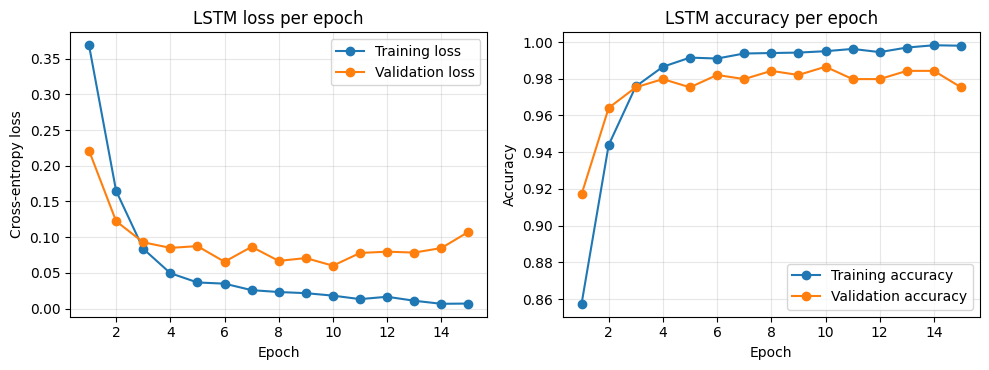

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3.8))
ep = range(1, EPOCHS + 1)
ax[0].plot(ep, hist["train_loss"], marker="o", label="Training loss")
ax[0].plot(ep, hist["val_loss"], marker="o", label="Validation loss")
ax[0].set_title("LSTM loss per epoch"); ax[0].set_xlabel("Epoch"); ax[0].set_ylabel("Cross-entropy loss")
ax[0].legend(); ax[0].grid(alpha=.3)
ax[1].plot(ep, hist["train_acc"], marker="o", label="Training accuracy")
ax[1].plot(ep, hist["val_acc"], marker="o", label="Validation accuracy")
ax[1].set_title("LSTM accuracy per epoch"); ax[1].set_xlabel("Epoch"); ax[1].set_ylabel("Accuracy")
ax[1].legend(); ax[1].grid(alpha=.3)
plt.tight_layout(); plt.savefig("figures/loss_curve.png", dpi=150); plt.show()

## 7. Final test accuracy (snapshot 4)

In [8]:
te = DataLoader(test_ds, 256)
preds = []
lstm.eval()
with torch.no_grad():
    for x, l, y in te:
        preds.append(lstm(x, l).argmax(1))
preds = torch.cat(preds).numpy(); truth = test_ds.y.numpy()

TARGET = 0.96
acc = (preds == truth).mean()
print(f"Test accuracy : {acc*100:.2f}%")
print(f"Baseline      : {BASELINE*100:.2f}%   (beaten by {100*(acc-BASELINE):.2f} points)")
print(f"Target        : {TARGET*100:.2f}%   ({'reached' if acc >= TARGET else 'not reached'})")
print()
print(classification_report(truth, preds, target_names=["ham", "spam"], digits=3))

Test accuracy : 98.57%
Baseline      : 86.64%   (beaten by 11.93 points)
Target        : 96.00%   (reached)

              precision    recall  f1-score   support

         ham      0.990     0.994     0.992       966
        spam      0.959     0.933     0.946       149

    accuracy                          0.986      1115
   macro avg      0.974     0.963     0.969      1115
weighted avg      0.986     0.986     0.986      1115



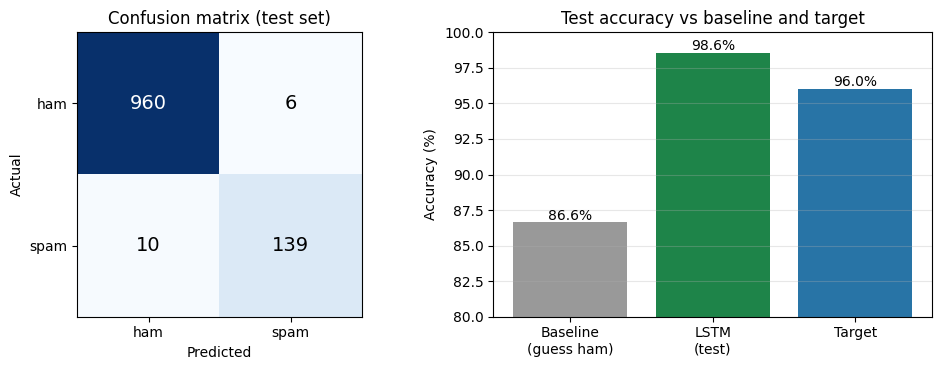

In [9]:
cm = confusion_matrix(truth, preds)
fig, ax = plt.subplots(1, 2, figsize=(10, 3.8))
im = ax[0].imshow(cm, cmap="Blues")
ax[0].set_xticks([0, 1]); ax[0].set_xticklabels(["ham", "spam"])
ax[0].set_yticks([0, 1]); ax[0].set_yticklabels(["ham", "spam"])
ax[0].set_xlabel("Predicted"); ax[0].set_ylabel("Actual"); ax[0].set_title("Confusion matrix (test set)")
for i in range(2):
    for j in range(2):
        ax[0].text(j, i, cm[i, j], ha="center", va="center",
                   color="white" if cm[i, j] > cm.max()/2 else "black", fontsize=14)
names = ["Baseline\n(guess ham)", "LSTM\n(test)", "Target"]
vals = [BASELINE*100, acc*100, TARGET*100]
bars = ax[1].bar(names, vals, color=["#999999", "#1e8449", "#2874a6"])
ax[1].set_ylim(80, 100); ax[1].set_ylabel("Accuracy (%)"); ax[1].set_title("Test accuracy vs baseline and target")
for b, v in zip(bars, vals): ax[1].text(b.get_x()+b.get_width()/2, v+0.2, f"{v:.1f}%", ha="center")
ax[1].grid(axis="y", alpha=.3)
plt.tight_layout(); plt.savefig("figures/final_result.png", dpi=150); plt.show()

## 8. Extra check: how stable is the result? (LSTM vs plain RNN over 5 seeds)
A single run can be lucky. The same experiment is repeated with 5 random seeds for both `nn.LSTM` and `nn.RNN`. The headline result above is seed 42, chosen before looking at any test results.

In [10]:
rows = []
for seed in [42, 7, 21, 99, 123]:
    for cell in ["LSTM", "RNN"]:
        if cell == "LSTM" and seed == SEED:
            rows.append(dict(seed=seed, model=cell, test_acc=acc * 100)); continue
        _, _, a = fit(cell, seed)
        rows.append(dict(seed=seed, model=cell, test_acc=a * 100))
    print("seed", seed, "done")
runs = pd.DataFrame(rows)
runs.to_csv("results_all_seeds.csv", index=False)

summary = runs.groupby("model")["test_acc"].agg(["mean", "std", "min", "max"]).round(2).loc[["RNN", "LSTM"]]
summary["baseline"] = round(BASELINE * 100, 2); summary["target"] = 96.0
summary.to_csv("results_summary.csv")
display(runs.pivot(index="seed", columns="model", values="test_acc")[["RNN", "LSTM"]].round(2))
display(summary)

seed 42 done


seed 7 done


seed 21 done


seed 99 done


seed 123 done


model,RNN,LSTM
seed,,
7,98.65,97.49
21,98.03,98.57
42,98.83,98.57
99,98.12,98.83
123,98.65,98.12


,mean,std,min,max,baseline,target
model,,,,,,
RNN,98.46,0.36,98.03,98.83,86.64,96.0
LSTM,98.31,0.53,97.49,98.83,86.64,96.0


## 9. Summary

In [11]:
print(f"LSTM (seed 42): {acc*100:.2f}% test accuracy | baseline {BASELINE*100:.1f}% | target 96%")
print(f"LSTM over 5 seeds: {summary.loc['LSTM','mean']:.2f}% +/- {summary.loc['LSTM','std']:.2f}")
print(f"RNN  over 5 seeds: {summary.loc['RNN','mean']:.2f}% +/- {summary.loc['RNN','std']:.2f}")

LSTM (seed 42): 98.57% test accuracy | baseline 86.6% | target 96%
LSTM over 5 seeds: 98.31% +/- 0.53
RNN  over 5 seeds: 98.46% +/- 0.36
